# Разделение говорящих

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SergeyShk/Speech-to-Text-Russian/blob/master/notebooks/06_speakers.ipynb)

В стереозаписи звонка каждый канал - свой говорящий. В записи с одного микрофона каналов нет, и разделять людей приходится по голосу. Здесь: как это включить, как выглядит результат, насколько он точен, когда указывать число говорящих и чего ждать от сведенного звонка.

## Установка

В Colab ячейка ставит stt-ru и `pandas`, `matplotlib`; в окружении, где пакет уже есть, ничего не делает.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("stt_ru") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "stt-ru[ffmpeg]", "pandas", "matplotlib"],
        check=True,
    )

## Записи

Чтобы было с чем сравнить результат, диалоги собраны из глав аудиокниг [LibriVox](https://librivox.org/) (общественное достояние): кто и когда говорит, здесь известно точно. Читают Марк Чульский ([«На краю света»](https://archive.org/details/on_the_edge_of_the_world_1902_librivox)), Ганна Пономаренко ([«Чортова кукла»](https://archive.org/details/chortova_kukla_2211_librivox)) и Xenium5 ([«Дубровский»](https://archive.org/details/dubrovsky_1411_librivox)).

Настоящий разговор труднее: реплики короче, люди перебивают друг друга, голоса записаны одним микрофоном. Цифры ниже - ориентир, а не обещание для ваших записей.

In [2]:
import time
import urllib.request
from itertools import permutations
from pathlib import Path

import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from stt_ru import Transcriber
from stt_ru.audio import Audio, load_audio
from stt_ru.diarization import Diarizer

pd.set_option("display.max_colwidth", None)
DATA = Path("data")
DATA.mkdir(exist_ok=True)
RATE = 16000
ARCHIVE = "https://archive.org/download"
BOOKS = {
    "Чульский": "on_the_edge_of_the_world_1902_librivox/edgeoftheworld_01_leskov_64kb.mp3",
    "Пономаренко": "chortova_kukla_2211_librivox/chortovakukla_00_gippius_64kb.mp3",
    "Xenium5": "dubrovsky_1411_librivox/dubrovsky_01_pushkin_64kb.mp3",
}


def listen(samples, sample_rate, name):
    # MP3 в несколько раз меньше WAV: звук плеера сохраняется в ноутбуке
    path = DATA / f"{name}.mp3"
    sf.write(path, samples, sample_rate)
    return ipd.Audio(filename=path)


chapters = {}
for reader, part in BOOKS.items():
    path = DATA / Path(part).name
    if not path.exists():
        urllib.request.urlretrieve(f"{ARCHIVE}/{part}", path)
    # Первые 30 с - объявление LibriVox, его читают по одному шаблону
    samples = load_audio(path, sample_rate=RATE).mono()[30 * RATE : 210 * RATE]
    chapters[reader] = samples / np.sqrt(np.mean(samples**2)) * 0.05
print({reader: f"{len(samples) / RATE:.0f} с" for reader, samples in chapters.items()})

{'Чульский': '180 с', 'Пономаренко': '180 с', 'Xenium5': '180 с'}


Распознавание нужно здесь дважды: фрагменты каждой главы дают границы фраз для диалога, а потом тем же объектом распознается сам диалог. Модель загружается один раз.

In [3]:
transcriber = Transcriber()
phrases = {
    reader: transcriber.transcribe_audio(Audio(samples[:, None], RATE)).segments
    for reader, samples in chapters.items()
}
{reader: len(found) for reader, found in phrases.items()}

{'Чульский': 47, 'Пономаренко': 55, 'Xenium5': 58}

In [4]:
def make_dialog(readers, seconds=150, seed=0):
    # Реплика - одна или несколько фраз подряд; фразы каждого чтеца идут по порядку
    rng = np.random.default_rng(seed)
    next_phrase = dict.fromkeys(readers, 0)
    pieces, truth = [], []
    position, last = 0.0, None
    while position < seconds:
        reader = rng.choice([name for name in readers if name != last] or readers)
        last = reader
        first = next_phrase[reader]
        count = int(rng.integers(1, 4))
        taken = phrases[reader][first : first + count]
        if not taken:
            break
        next_phrase[reader] = first + count
        begin = taken[0].start
        pieces.append(chapters[reader][int(begin * RATE) : int(taken[-1].end * RATE)])
        truth += [
            (position + p.start - begin, position + p.end - begin, str(reader)) for p in taken
        ]
        position += taken[-1].end - begin
        pause = rng.uniform(0.15, 0.7)
        pieces.append(np.zeros(int(pause * RATE), dtype=np.float32))
        position += pause
    return np.concatenate(pieces).astype(np.float32), truth


two, two_truth = make_dialog(["Чульский", "Пономаренко"], seed=1)
three, three_truth = make_dialog(list(BOOKS), seed=2)
one, one_truth = make_dialog(["Чульский"], seed=3)
DIALOG = DATA / "dialog.wav"
sf.write(DIALOG, two, RATE)
print(
    f"Двое: {len(two) / RATE:.0f} с, трое: {len(three) / RATE:.0f} с, один: {len(one) / RATE:.0f} с"
)
listen(two[: 40 * RATE], RATE, "dialog_start")

Двое: 158 с, трое: 164 с, один: 159 с


## Результат

`diarize=True` подписывает фрагменты «Говорящий 1», «Говорящий 2» по порядку появления в записи. Модели разделения (около 35 МБ) скачиваются при первом использовании. Параметр можно задать и сразу при создании `Transcriber`.

In [5]:
started = time.perf_counter()
result = transcriber.transcribe(DIALOG, diarize=True)
print(f"{result.duration:.0f} с записи за {time.perf_counter() - started:.1f} с")
frame = pd.DataFrame(
    {
        "начало": s.start,
        "конец": s.end,
        "говорящий": s.speaker,
        "текст": s.text,
    }
    for s in result.segments
)
frame.head(14)

158 с записи за 31.5 с


,начало,конец,говорящий,текст
0,0.002,4.030,Говорящий 1,"Мой наш хозяин, тогда уже весьма престарелый архиепископ."
1,4.290,6.014,Говорящий 1,Больной и немощный.
2,6.658,12.670,Говорящий 2,"Предисловие пишу, а скорее послесловие. Обращаюсь к тем из моих далёких читателей,"
3,13.346,15.614,Говорящий 1,Гости были люди просвещённые.
4,15.906,18.622,Говорящий 2,"которые читают роман, думая, что роман"
5,18.754,19.870,Говорящий 2,О революции.
6,20.610,21.598,Говорящий 2,И спрашивают.
7,22.178,27.102,Говорящий 1,И между ними шёл интересный разговор о нашей вере и о нашем неверии.
8,27.330,29.790,Говорящий 1,О нашем проповедничестве в храмах.
9,30.178,31.806,Говорящий 2,Можно ли говорить намёками?


## Лента разговора

Сверху - кто говорил на самом деле, снизу - что нашла диаризация. Номера говорящих ничего не знают об именах: важно только, что реплики одного человека получили один номер.

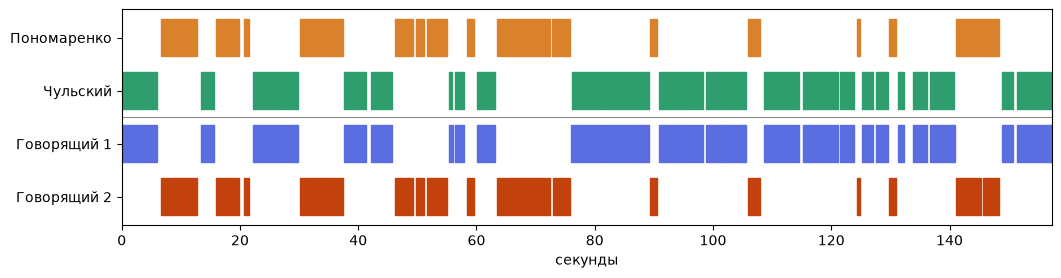

In [6]:
COLORS = ["#d9822b", "#2f9e6e", "#5b6ee1", "#c2410c", "#7c3aed", "#0891b2"]


def timeline(truth, found, end=None):
    names = sorted({name for _, _, name in truth})
    numbers = sorted({name for _, _, name in found})
    rows = [*names, *numbers]
    _, ax = plt.subplots(figsize=(12, 0.5 * len(rows) + 0.8))
    for row, name in enumerate(rows):
        items = truth if row < len(names) else found
        bars = [(start, stop - start) for start, stop, who in items if who == name]
        ax.broken_barh(bars, (row - 0.35, 0.7), color=COLORS[row % len(COLORS)])
    ax.axhline(len(names) - 0.5, color="#888", linewidth=0.8)
    ax.set_yticks(range(len(rows)), rows)
    ax.invert_yaxis()
    ax.set_xlim(0, end or max(stop for _, stop, _ in truth))
    ax.set_xlabel("секунды")
    plt.show()


found = [(s.start, s.end, s.speaker) for s in result.segments]
timeline(two_truth, found)

## Точность

Простая мера: какая доля времени речи досталась верному человеку, если номера сопоставить с именами наилучшим образом.

In [7]:
def share_correct(truth, found, duration, step=0.01):
    def activity(items):
        names = sorted({name for _, _, name in items})
        rows = np.zeros((len(names), int(duration / step) + 2), dtype=bool)
        for start, stop, name in items:
            rows[names.index(name), int(start / step) : int(stop / step)] = True
        return rows

    reference, hypothesis = activity(truth), activity(found)
    overlap = reference.astype(np.int64) @ hypothesis.T.astype(np.int64)
    if overlap.shape[0] > overlap.shape[1]:
        overlap = overlap.T
    best = max(
        sum(overlap[row, column] for row, column in enumerate(order))
        for order in permutations(range(overlap.shape[1]), overlap.shape[0])
    )
    return best / reference.sum()


print(f"Верный говорящий: {share_correct(two_truth, found, result.duration):.1%} времени речи")

Верный говорящий: 99.6% времени речи


## Сколько говорящих

Без подсказки число говорящих определяется по записи. Если оно известно, его лучше указать в `speakers`: так найдутся и те, кто говорит мало. Число меньше настоящего сливает людей, больше настоящего почти не вредит.

`Diarizer` находит реплики без распознавания: это быстрее, когда текст не нужен.

In [8]:
diarizer = transcriber.diarizer
cases = [
    ("один чтец", one, one_truth, None),
    ("один чтец", one, one_truth, 2),
    ("двое", two, two_truth, None),
    ("двое", two, two_truth, 2),
    ("двое", two, two_truth, 1),
    ("двое", two, two_truth, 3),
    ("трое", three, three_truth, None),
    ("трое", three, three_truth, 3),
]
rows = []
for name, samples, truth, speakers in cases:
    started = time.perf_counter()
    turns = diarizer.diarize(samples, RATE, speakers=speakers)
    spent = time.perf_counter() - started
    items = [(t.start, t.end, str(t.speaker)) for t in turns]
    rows.append(
        {
            "запись": name,
            "speakers": speakers or "авто",
            "найдено": len({t.speaker for t in turns}),
            "верный говорящий": f"{share_correct(truth, items, len(samples) / RATE):.1%}",
            "быстрее записи, раз": round(len(samples) / RATE / spent),
        }
    )
pd.DataFrame(rows)

,запись,speakers,найдено,верный говорящий,"быстрее записи, раз"
0,один чтец,авто,1,99.2%,18
1,один чтец,2,1,99.2%,19
2,двое,авто,2,97.5%,16
3,двое,2,2,97.5%,15
4,двое,1,1,62.4%,15
5,двое,3,3,96.8%,15
6,трое,авто,3,91.1%,17
7,трое,3,3,91.1%,16


Порог `threshold` у `Diarizer` решает, насколько разные отпечатки считать разными людьми: чем он больше, тем меньше говорящих. Значение по умолчанию подобрано по записям с разным числом людей. Менять его стоит, только если на ваших записях говорящие стабильно дробятся или сливаются, а число людей заранее неизвестно.

In [9]:
rows = []
for threshold in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0):
    tuned = Diarizer(threshold=threshold)
    row = {"threshold": threshold}
    for name, samples, truth in (("двое", two, two_truth), ("трое", three, three_truth)):
        turns = tuned.diarize(samples, RATE)
        items = [(t.start, t.end, str(t.speaker)) for t in turns]
        row[f"{name}: найдено"] = len({t.speaker for t in turns})
        row[f"{name}: верно"] = f"{share_correct(truth, items, len(samples) / RATE):.1%}"
    rows.append(row)
pd.DataFrame(rows)

,threshold,двое: найдено,двое: верно,трое: найдено,трое: верно
0,0.5,3,91.4%,5,84.2%
1,0.6,2,97.5%,3,91.1%
2,0.7,2,97.5%,3,91.1%
3,0.8,2,97.5%,2,68.0%
4,0.9,2,97.5%,2,68.0%
5,1.0,2,97.5%,2,68.0%


## Смена говорящего без паузы

Поиск речи режет запись по паузам. Если один человек вступает сразу за другим, это один фрагмент, и без разделения он достается одному говорящему. С разделением фрагмент делится по словам, а текст остается тем же. Модели без времени слов (Whisper) отдают такой фрагмент целиком тому, кто говорит в нем дольше всех.

In [10]:
first = phrases["Чульский"][4]
second = phrases["Пономаренко"][4]
joined = np.concatenate(
    [
        chapters["Чульский"][int(first.start * RATE) : int(first.end * RATE)],
        chapters["Пономаренко"][int(second.start * RATE) : int(second.end * RATE)],
    ]
).astype(np.float32)
audio = Audio(joined[:, None], RATE)
for title, options in (("Без разделения", {}), ("С разделением", {"speakers": 2})):
    print(title)
    for s in transcriber.transcribe_audio(audio, **options).segments:
        print(f"  {s.start:5.1f}-{s.end:5.1f} {s.speaker or '-'}: {s.text}")
listen(joined, RATE, "joined")

Без разделения
    0.0-  4.1 -: О нашем проповедничестве в храмах. Можно ли говорить намёками?
С разделением
    0.0-  2.6 Говорящий 1: О нашем проповедничестве в храмах.
    2.6-  4.1 Говорящий 2: Можно ли говорить намёками?


## Сведенный звонок

Разные каналы и так разделяют говорящих, поэтому для стереозаписи `diarize` только выводит предупреждение. Если нужно разделить людей именно в сведенной записи, каналы сводятся в один: здесь это сделано сохранением в файл, а в `Transcriber` и в команде для этого есть `split_channels=False` и `--mono`.

Каналы дают настоящую разметку, а заодно показывают предел метода: распознавание слышит одну дорожку, и короткое «Угу» поверх речи оператора в сведенной записи теряется, хотя в своем канале оно есть.

In [11]:
CALL = DATA / "call.wav"
if not CALL.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SergeyShk/Speech-to-Text-Russian/master/tests/data/call.wav",
        CALL,
    )
stereo = transcriber.transcribe(CALL, diarize=True)
print("Стереозапись")
for s in stereo.segments:
    print(f"  {s.start:5.1f}-{s.end:5.1f} {s.speaker}: {s.text}")

audio = load_audio(CALL)
MIXED = DATA / "call_mixed.wav"
sf.write(MIXED, audio.mono(), audio.sample_rate)
mixed = transcriber.transcribe(MIXED, speakers=2)
print("Сведенная запись")
for s in mixed.segments:
    print(f"  {s.start:5.1f}-{s.end:5.1f} {s.speaker}: {s.text}")
listen(audio.mono(), audio.sample_rate, "call_mixed")

/Users/shkarin/Projects/Speech-to-Text-Russian/src/stt_ru/pipeline.py:158: UserWarning: call.wav: каналы разные, каждый считается говорящим; чтобы разделить говорящих в сведенной записи, нужно сводить каналы в один
  return self.transcribe_audio(


Стереозапись
    1.0-  9.1 Канал 1: Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.
    3.5-  3.9 Канал 0: Угу
    7.7-  8.2 Канал 0: Угу
    9.6- 12.6 Канал 1: Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.
   13.0- 13.7 Канал 0: До свидания.
Сведенная запись
    1.0-  8.9 Говорящий 1: Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.
    9.6- 12.6 Говорящий 1: Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.
   13.0- 13.7 Говорящий 2: До свидания.


Верный говорящий: 91.0% времени речи


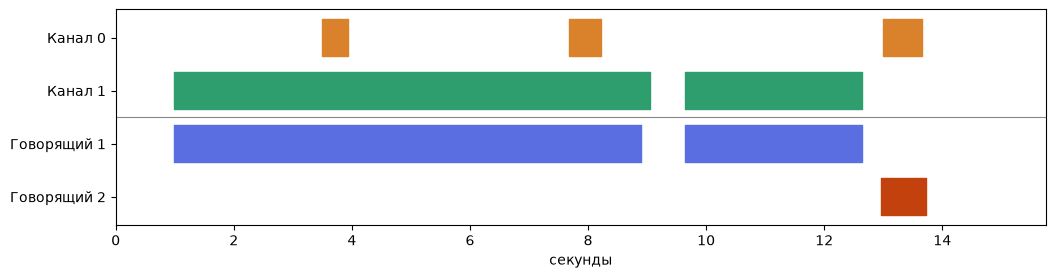

In [12]:
call_truth = [(s.start, s.end, s.speaker) for s in stereo.segments]
call_found = [(s.start, s.end, s.speaker) for s in mixed.segments]
print(
    f"Верный говорящий: {share_correct(call_truth, call_found, mixed.duration):.1%} времени речи"
)
timeline(call_truth, call_found, mixed.duration)

## Командная строка

`--diarize` определяет число говорящих по записи, `--speakers N` задает его; результат подписан во всех форматах. У `transcribe` значения относятся ко всем файлам запуска.

In [13]:
%%bash
stt-ru transcribe data/dialog.wav --speakers 2 -f srt -q | head -12
echo "---"
stt-ru transcribe data/dialog.wav --speakers 2 -f jsonl -q | head -2

1
00:00:00,002 --> 00:00:04,030
Говорящий 1: Мой наш хозяин, тогда уже весьма престарелый архиепископ.

2
00:00:04,290 --> 00:00:06,014
Говорящий 1: Больной и немощный.

3
00:00:06,658 --> 00:00:12,670
Говорящий 2: Предисловие пишу, а скорее послесловие. Обращаюсь к тем из моих далёких читателей,

---
{"source": "dialog.wav", "start": 0.002, "end": 4.03, "channel": null, "speaker_id": 1, "speaker": "Говорящий 1", "text": "Мой наш хозяин, тогда уже весьма престарелый архиепископ."}
{"source": "dialog.wav", "start": 4.29, "end": 6.014, "channel": null, "speaker_id": 1, "speaker": "Говорящий 1", "text": "Больной и немощный."}


## Веб-сервис

В [веб-интерфейсе](https://sergeyshk.github.io/Speech-to-Text-Russian/service/) перед загрузкой можно включить флажок «Разделять говорящих» и указать их число для этой записи. В REST API то же задают поля формы (сервис запущен как в [ноутбуке про веб-сервис](05_web_service.ipynb)):

``` python
with open("data/dialog.wav", "rb") as file:
    job = requests.post(f"{api}/transcriptions", files={"file": file}, data={"speakers": 2}).json()
```

`diarize=false` выключает разделение для одной задачи, если сервис запущен с `--diarize`.